Himalayan Database — Data Cleaning & Preprocessing

This notebook takes the **raw** Himalayan Database files (`members.csv`,
`peaks.csv`) and walks through every preprocessing step needed to produce
`himalayan_climbers_clean.csv` — the modeling-ready dataset used in the
stacking-ensemble notebook.

**Inputs (place in the same folder as this notebook):**
- `members.csv` — 76,519 rows x 21 columns, one row per climber per expedition
- `peaks.csv` — 468 rows x 8 columns, mountain-level metadata

**Output:** `himalayan_climbers_clean.csv` — ~73,000 rows x 15 columns
(14 features + `died` target), 0 missing values.

**Source:** [Himalayan Database](https://himalayandatabase.com), via the
[R4DS TidyTuesday repo](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-09-22).


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', None)


1. Load the raw files

In [6]:
for f in ['RawData/members.csv', 'RawData/peaks.csv']:
    if not os.path.exists(f):
        raise FileNotFoundError(f"Could not find '{f}' — place it in the same folder as this notebook.")

members = pd.read_csv('RawData/members.csv')
peaks = pd.read_csv('RawData/peaks.csv')

print(f"members: {members.shape}")
print(f"peaks:   {peaks.shape}")
members.head()


members: (76519, 21)
peaks:   (468, 8)


,expedition_id,member_id,peak_id,peak_name,year,season,sex,age,citizenship,expedition_role,hired,highpoint_metres,success,solo,oxygen_used,died,death_cause,death_height_metres,injured,injury_type,injury_height_metres
0,AMAD78301,AMAD78301-01,AMAD,Ama Dablam,1978,Autumn,M,40.0,France,Leader,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN
1,AMAD78301,AMAD78301-02,AMAD,Ama Dablam,1978,Autumn,M,41.0,France,Deputy Leader,False,6000.0,False,False,False,False,NaN,NaN,False,NaN,NaN
2,AMAD78301,AMAD78301-03,AMAD,Ama Dablam,1978,Autumn,M,27.0,France,Climber,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN
3,AMAD78301,AMAD78301-04,AMAD,Ama Dablam,1978,Autumn,M,40.0,France,Exp Doctor,False,6000.0,False,False,False,False,NaN,NaN,False,NaN,NaN
4,AMAD78301,AMAD78301-05,AMAD,Ama Dablam,1978,Autumn,M,34.0,France,Climber,False,NaN,False,False,False,False,NaN,NaN,False,NaN,NaN


 2. Explore the raw data

In [7]:
members.dtypes


expedition_id            object
member_id                object
peak_id                  object
peak_name                object
year                      int64
season                   object
sex                      object
age                     float64
citizenship              object
expedition_role          object
hired                      bool
highpoint_metres        float64
success                    bool
solo                       bool
oxygen_used                bool
died                       bool
death_cause              object
death_height_metres     float64
injured                    bool
injury_type              object
injury_height_metres    float64
dtype: object

In [8]:
# Missing values as a % of rows
missing_pct = (members.isna().mean() * 100).round(1).sort_values(ascending=False)
missing_pct


injury_height_metres    98.7
death_height_metres     98.6
death_cause             98.6
injury_type             97.8
highpoint_metres        28.5
age                      4.6
injured                  0.0
died                     0.0
oxygen_used              0.0
solo                     0.0
success                  0.0
expedition_id            0.0
member_id                0.0
expedition_role          0.0
citizenship              0.0
sex                      0.0
season                   0.0
year                     0.0
peak_name                0.0
peak_id                  0.0
hired                    0.0
dtype: float64

In [9]:
print("Target class balance (died):")
print(members['died'].value_counts())
print(f"Death rate: {members['died'].mean():.4f}")


Target class balance (died):
died
False    75413
True      1106
Name: count, dtype: int64
Death rate: 0.0145


 3. Merge in peak-level metadata

`highpoint_metres` (how high *this climber* got) is missing for ~28.5% of
rows and is arguably a post-outcome variable anyway (you don't know your own
highpoint before you climb). Instead we bring in the **mountain's official
height** from `peaks.csv` — a static, always-available property of the peak
that's a legitimate pre-climb feature (taller/more technical peaks are
generally more dangerous).


In [10]:
peaks_small = peaks[['peak_id', 'height_metres']]
members = members.merge(peaks_small, on='peak_id', how='left')

print(f"Rows after merge: {len(members)}")
print(f"Missing height_metres after merge: {members['height_metres'].isna().sum()}")


Rows after merge: 76519
Missing height_metres after merge: 15


4. Engineer an expedition-size feature

The number of members on an expedition is a reasonable proxy for how
well-resourced/organized a climb is (larger expeditions often have more
logistical and safety support). We compute this from `members.csv` itself
before any row filtering, so it reflects the true original expedition size.


In [11]:
members['expedition_size'] = members.groupby('expedition_id')['member_id'].transform('count')
members[['expedition_id', 'expedition_size']].drop_duplicates().head()


,expedition_id,expedition_size
0,AMAD78301,9
8,AMAD79101,18
25,AMAD79301,26
51,AMAD79302,5
55,AMAD79303,5


5. Drop rows with missing values on features we're keeping

We only need to drop rows missing `age` or `height_metres` (the merged peak
height) — every other feature we plan to use is fully populated. This is a
small fraction of rows, so we lose minimal data while keeping the "minimal
missing values" property required for the final dataset.


In [12]:
before = len(members)
members = members.dropna(subset=['age', 'height_metres'])
after = len(members)

print(f"Rows before: {before:,}")
print(f"Rows after:  {after:,}")
print(f"Dropped: {before - after:,} ({(before - after) / before:.1%})")


Rows before: 76,519
Rows after:  73,007
Dropped: 3,512 (4.6%)


6. Engineer a leakage-safe historical peak-risk feature

importnant xa yo part chai sab le bujna parne xa.engineered feature. Some peaks (K2, Annapurna I)
are known to be far deadlier than others (Ama Dablam), but the model has no
way to know that from raw categorical peak names alone once we bucket rare
peaks into "Other" (next step).

**The risk of doing this naively:** if we compute each peak's overall death
rate using *all* years of data (including years after the row we're
predicting), we leak the future into the past — the model would effectively
be told the outcome distribution it's trying to predict.

**The fix:** for every row, we only look at climbs on that peak that happened
in **strictly earlier years**. This is a proper expanding/rolling calculation,
safe to use as a real pre-climb risk signal.


In [13]:
# Peak x year level death counts
yearly = members.groupby(['peak_id', 'year']).agg(
    n=('died', 'size'), deaths=('died', 'sum')
).reset_index().sort_values(['peak_id', 'year'])

# Cumulative totals STRICTLY BEFORE the current year (shift by excluding current year's own count)
yearly['cum_n_prior'] = yearly.groupby('peak_id')['n'].cumsum() - yearly['n']
yearly['cum_deaths_prior'] = yearly.groupby('peak_id')['deaths'].cumsum() - yearly['deaths']

yearly.head()


,peak_id,year,n,deaths,cum_n_prior,cum_deaths_prior
0,ACHN,2015,16,0,0,0
1,ACHN,2018,9,0,16,0
2,AMAD,1958,4,0,0,0
3,AMAD,1959,7,2,4,0
4,AMAD,1961,5,0,11,2


In [14]:
# Global (all-peaks) expanding rate as a fallback for peaks/years with too little prior history
global_yearly = members.groupby('year').agg(
    n=('died', 'size'), deaths=('died', 'sum')
).reset_index().sort_values('year')

global_yearly['cum_n_prior'] = global_yearly['n'].cumsum() - global_yearly['n']
global_yearly['cum_deaths_prior'] = global_yearly['deaths'].cumsum() - global_yearly['deaths']
global_yearly['global_rate'] = np.where(
    global_yearly['cum_n_prior'] > 0,
    global_yearly['cum_deaths_prior'] / global_yearly['cum_n_prior'],
    members['died'].mean()  # fallback for the very first year in the dataset
)

global_yearly[['year', 'global_rate']].head()


,year,global_rate
0,1905,0.012725
1,1907,0.000000
2,1909,0.000000
3,1910,0.000000
4,1920,0.000000


In [15]:
members = members.merge(yearly[['peak_id', 'year', 'cum_n_prior', 'cum_deaths_prior']],
                         on=['peak_id', 'year'], how='left')
members = members.merge(global_yearly[['year', 'global_rate']], on='year', how='left')

MIN_PRIOR_CLIMBS = 20  # require this many prior climbs before trusting the peak-specific rate

members['peak_hist_fatality_rate'] = np.where(
    members['cum_n_prior'] >= MIN_PRIOR_CLIMBS,
    members['cum_deaths_prior'] / members['cum_n_prior'],
    members['global_rate']
)
members['peak_hist_climbs'] = members['cum_n_prior'].fillna(0)

members[['peak_name', 'year', 'peak_hist_climbs', 'peak_hist_fatality_rate']].sample(5, random_state=1)


,peak_name,year,peak_hist_climbs,peak_hist_fatality_rate
25725,Everest,1971,418,0.033493
71160,Manaslu,2018,4162,0.017780
48941,Everest,1938,105,0.038095
31436,Everest,2003,7405,0.019446
25352,Cho Oyu,1958,27,0.000000


7. Bucket high-cardinality categorical columns

`peak_name`, `citizenship`, and `expedition_role` have many rare categories
that would each become a near-empty one-hot column (mostly noise, and
inflates dimensionality). We keep the top-15 most frequent values for
`peak_name`/`citizenship` and group the rest into `"Other"`, and manually
group `expedition_role` into four broader, more meaningful buckets.


In [16]:
print("Peaks by frequency (top 10):")
print(members['peak_name'].value_counts().head(10))
print()
print("Citizenship by frequency (top 10):")
print(members['citizenship'].value_counts().head(10))
print()
print("Expedition role by frequency:")
print(members['expedition_role'].value_counts())


Peaks by frequency (top 10):
peak_name
Everest         20997
Cho Oyu          8608
Ama Dablam       8236
Manaslu          4510
Dhaulagiri I     2503
Lhotse           2335
Makalu           2334
Baruntse         2125
Pumori           1725
Annapurna I      1617
Name: count, dtype: int64

Citizenship by frequency (top 10):
citizenship
Nepal          14369
USA             6320
Japan           6188
UK              5072
France          4501
Spain           3301
S Korea         2885
Italy           2719
Germany         2638
Switzerland     2414
Name: count, dtype: int64

Expedition role by frequency:
expedition_role
Climber                  43316
H-A Worker               13033
Leader                    9885
Exp Doctor                1411
Deputy Leader             1225
                         ...  
Exp Interpreter              1
General Commander            1
Secretary/interpreter        1
Dep Ldr/Organizer            1
Exp Docter                   1
Name: count, Length: 483, dtype: int64


In [17]:
top_peaks = members['peak_name'].value_counts().nlargest(15).index
members['peak_name_grp'] = np.where(members['peak_name'].isin(top_peaks), members['peak_name'], 'Other')

top_citz = members['citizenship'].value_counts().nlargest(15).index
members['citizenship_grp'] = np.where(members['citizenship'].isin(top_citz), members['citizenship'], 'Other')

role_map = {
    'Climber': 'Climber', 'Member': 'Climber',
    'H-A Worker': 'H-A Worker', 'Sirdar': 'H-A Worker', 'H-A Assistant': 'H-A Worker',
    'Leader': 'Leader', 'Deputy Leader': 'Leader', 'Climbing Leader': 'Leader',
    'Exp Doctor': 'Other', 'BC Manager': 'Other',
}
members['expedition_role_grp'] = members['expedition_role'].map(role_map).fillna('Other')

print(f"peak_name:        {members['peak_name'].nunique()} -> {members['peak_name_grp'].nunique()} categories")
print(f"citizenship:      {members['citizenship'].nunique()} -> {members['citizenship_grp'].nunique()} categories")
print(f"expedition_role:  {members['expedition_role'].nunique()} -> {members['expedition_role_grp'].nunique()} categories")


peak_name:        390 -> 16 categories
citizenship:      207 -> 16 categories
expedition_role:  483 -> 4 categories


8. Select final features, rename, and finalize types

We exclude the outcome-leaking columns identified in step 2
(`death_cause`, `death_height_metres`, `injury_type`, `injury_height_metres`,
`injured`), the raw ID columns, and the pre-bucketed categorical columns
(replaced by their `_grp` versions).


In [18]:
final_cols = ['year', 'season', 'peak_name_grp', 'height_metres', 'age', 'sex',
              'citizenship_grp', 'expedition_role_grp', 'hired', 'solo',
              'oxygen_used', 'expedition_size', 'peak_hist_fatality_rate',
              'peak_hist_climbs', 'died']

df = members[final_cols].copy()
df.columns = ['year', 'season', 'peak_name', 'peak_height_m', 'age', 'sex',
              'citizenship', 'expedition_role', 'hired', 'solo',
              'oxygen_used', 'expedition_size', 'peak_hist_fatality_rate',
              'peak_hist_climbs', 'died']

# Booleans -> int for modeling convenience
for c in ['hired', 'solo', 'oxygen_used', 'died']:
    df[c] = df[c].astype(int)

# Shuffle rows (the raw data is roughly chronological; shuffling avoids any
# ordering artifacts if a downstream tool does a naive head()-based split)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

df.head()


,year,season,peak_name,peak_height_m,age,sex,citizenship,expedition_role,hired,solo,oxygen_used,expedition_size,peak_hist_fatality_rate,peak_hist_climbs,died
0,2014,Autumn,Manaslu,8163.0,30.0,M,Nepal,H-A Worker,1,0,1,20,0.023004,3043,0
1,1999,Autumn,Other,7227.0,29.0,M,Spain,Climber,0,0,0,5,0.048507,268,0
2,1997,Autumn,Ama Dablam,6814.0,27.0,M,USA,Climber,0,0,0,8,0.007488,1202,0
3,1996,Autumn,Manaslu,8163.0,25.0,M,Italy,Climber,0,0,0,10,0.042986,884,0
4,2003,Spring,Everest,8850.0,37.0,M,Other,Climber,0,0,0,17,0.019446,7405,0


9. Final checks

In [19]:
print(f"Shape: {df.shape}")
print(f"Total missing values: {df.isna().sum().sum()}")
print(f"Death rate: {df['died'].mean():.4f}  (positive cases: {df['died'].sum()})")
print()
print(df.dtypes)


Shape: (73007, 15)
Total missing values: 0
Death rate: 0.0127  (positive cases: 929)

year                         int64
season                      object
peak_name                   object
peak_height_m              float64
age                        float64
sex                         object
citizenship                 object
expedition_role             object
hired                        int64
solo                         int64
oxygen_used                  int64
expedition_size              int64
peak_hist_fatality_rate    float64
peak_hist_climbs             int64
died                         int64
dtype: object


In [20]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,73007.0,NaN,NaN,NaN,2001.001616,14.126299,1905.0,1992.0,2004.0,2012.0,2019.0
season,73007,4,Spring,36167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peak_name,73007,16,Everest,20997,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peak_height_m,73007.0,NaN,NaN,NaN,7936.752092,836.667068,5407.0,7138.0,8167.0,8850.0,8850.0
age,73007.0,NaN,NaN,NaN,37.335721,10.394613,7.0,29.0,36.0,44.0,85.0
sex,73007,2,M,66171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
citizenship,73007,16,Nepal,14369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expedition_role,73007,4,Climber,43614,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hired,73007.0,NaN,NaN,NaN,0.191488,0.393475,0.0,0.0,0.0,0.0,1.0
solo,73007.0,NaN,NaN,NaN,0.001589,0.039829,0.0,0.0,0.0,0.0,1.0


10. Save the cleaned dataset

In [21]:
OUT_PATH = 'CleanData/himalayan_climbers_clean.csv'
df.to_csv(OUT_PATH, index=False)
print(f"Saved {len(df):,} rows x {df.shape[1]} columns to '{OUT_PATH}'")


Saved 73,007 rows x 15 columns to 'himalayan_climbers_clean.csv'


11. Feature selection

Before splitting/modeling, we check whether every engineered/retained feature
actually carries predictive signal, rather than assuming it does. We fit a
quick, untuned Random Forest on the **full** cleaned dataset purely to rank
feature importances — this model is diagnostic only and is discarded
afterward; it is not one of the five models used later.


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

feature_cols = [c for c in df.columns if c != 'died']
numeric_cols = ['year', 'peak_height_m', 'age', 'expedition_size',
                 'peak_hist_fatality_rate', 'peak_hist_climbs']
binary_cols = ['hired', 'solo', 'oxygen_used']
categorical_cols = ['season', 'peak_name', 'sex', 'citizenship', 'expedition_role']

diag_preprocessor = ColumnTransformer([
    ('num', 'passthrough', numeric_cols + binary_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])

diag_pipeline = Pipeline([
    ('prep', diag_preprocessor),
    ('clf', RandomForestClassifier(n_estimators=300, max_depth=8, class_weight='balanced',
                                    random_state=RANDOM_STATE, n_jobs=-1)),
])

diag_pipeline.fit(df[feature_cols], df['died'])

ohe_names = diag_pipeline.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_names = numeric_cols + binary_cols + list(ohe_names)
importances = diag_pipeline.named_steps['clf'].feature_importances_

# Roll one-hot columns back up to their parent categorical feature (sum of importances)
imp_series = pd.Series(importances, index=all_names)
rolled = {}
for col in numeric_cols + binary_cols:
    rolled[col] = imp_series[col]
for col in categorical_cols:
    rolled[col] = imp_series[[n for n in all_names if n.startswith(col + '_')]].sum()

feature_importance = pd.Series(rolled).sort_values(ascending=False)
feature_importance


peak_hist_fatality_rate    0.172330
year                       0.147580
peak_name                  0.115551
peak_hist_climbs           0.111377
peak_height_m              0.097794
citizenship                0.089994
expedition_size            0.073773
age                        0.056389
expedition_role            0.045269
season                     0.030528
oxygen_used                0.021889
sex                        0.020181
hired                      0.015867
solo                       0.001477
dtype: float64

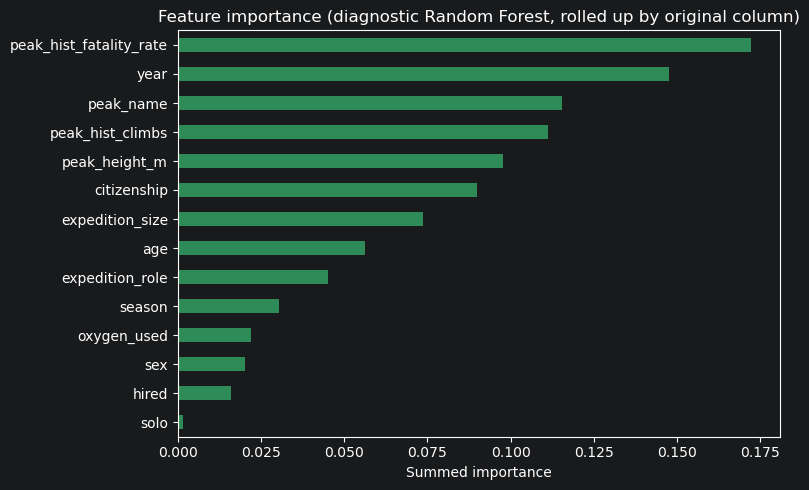

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
feature_importance.sort_values().plot(kind='barh', ax=ax, color='seagreen')
ax.set_title('Feature importance (diagnostic Random Forest, rolled up by original column)')
ax.set_xlabel('Summed importance')
plt.tight_layout()
plt.show()


In [24]:
IMPORTANCE_THRESHOLD = 0.01  # drop features contributing less than 1% combined importance

weak_features = feature_importance[feature_importance < IMPORTANCE_THRESHOLD].index.tolist()

if weak_features:
    print(f"Dropping low-importance features (< {IMPORTANCE_THRESHOLD}): {weak_features}")
    df = df.drop(columns=weak_features)
else:
    print(f"No feature fell below the {IMPORTANCE_THRESHOLD} importance threshold — all "
          f"{len(feature_importance)} features are retained.")

print(f"Final feature set ({df.shape[1] - 1} features + target):")
print([c for c in df.columns if c != 'died'])


Dropping low-importance features (< 0.01): ['solo']
Final feature set (13 features + target):
['year', 'season', 'peak_name', 'peak_height_m', 'age', 'sex', 'citizenship', 'expedition_role', 'hired', 'oxygen_used', 'expedition_size', 'peak_hist_fatality_rate', 'peak_hist_climbs']


12. Train / test split

We split **before** any scaling, and stratify on `died` so both the train
and test sets preserve the same ~1.3% death rate — critical given how
imbalanced this target is (a random, non-stratified split risks a test set
with very few or even zero positive cases).


In [25]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['died'])
y = df['died']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]:,} rows | death rate: {y_train.mean():.4f} | deaths: {y_train.sum()}")
print(f"Test:  {X_test.shape[0]:,} rows | death rate: {y_test.mean():.4f} | deaths: {y_test.sum()}")


Train: 58,405 rows | death rate: 0.0127 | deaths: 743
Test:  14,602 rows | death rate: 0.0127 | deaths: 186


13. Feature scaling (demonstrated)

We fit `StandardScaler` on the **training set only** and apply it to both
train and test — fitting on the full dataset (or on train+test combined)
would leak test-set statistics (mean/variance) into training, a subtle but
real form of data leakage.

This step is shown here for documentation purposes. In the modeling
notebook, scaling is re-applied **inside each model's own pipeline** so
that during cross-validation and hyperparameter search, the scaler is
re-fit on each training fold rather than reusing these global statistics —
the same principle, applied correctly at the fold level rather than once
globally.


In [26]:
from sklearn.preprocessing import StandardScaler

remaining_numeric = [c for c in numeric_cols if c in X_train.columns]

scaler = StandardScaler()
X_train_scaled_demo = X_train.copy()
X_test_scaled_demo = X_test.copy()

X_train_scaled_demo[remaining_numeric] = scaler.fit_transform(X_train[remaining_numeric])
X_test_scaled_demo[remaining_numeric] = scaler.transform(X_test[remaining_numeric])

print("Before scaling (train):")
print(X_train[remaining_numeric].describe().loc[['mean', 'std']].round(2))
print()
print("After scaling (train):")
print(X_train_scaled_demo[remaining_numeric].describe().loc[['mean', 'std']].round(2))


Before scaling (train):
         year  peak_height_m    age  expedition_size  peak_hist_fatality_rate  \
mean  2000.98        7934.71  37.32            13.58                     0.02   
std     14.14         837.09  10.37            11.53                     0.02   

      peak_hist_climbs  
mean           4207.47  
std            5274.36  

After scaling (train):
      year  peak_height_m  age  expedition_size  peak_hist_fatality_rate  \
mean  -0.0           -0.0  0.0              0.0                      0.0   
std    1.0            1.0  1.0              1.0                      1.0   

      peak_hist_climbs  
mean               0.0  
std                1.0  


14. Save the split datasets

In [27]:
train_out = X_train.copy()
train_out['died'] = y_train
test_out = X_test.copy()
test_out['died'] = y_test

train_out.to_csv('CleanData/himalayan_train.csv', index=False)
test_out.to_csv('CleanData/himalayan_test.csv', index=False)

print(f"Saved himalayan_train.csv ({train_out.shape[0]:,} rows) "
      f"and himalayan_test.csv ({test_out.shape[0]:,} rows)")
print("(unscaled — the modeling notebook applies scaling inside each model's own pipeline)")


Saved himalayan_train.csv (58,405 rows) and himalayan_test.csv (14,602 rows)
(unscaled — the modeling notebook applies scaling inside each model's own pipeline)


## Summary of preprocessing decisions

| Step | Decision | Why |
|---|---|---|
| Outcome-only columns (`death_cause`, `injury_type`, etc.) | Dropped entirely | Non-null only when the outcome occurred — using them as features would leak the target |
| `highpoint_metres` (28.5% missing) | Dropped, replaced with peak's official height | Also a post-outcome variable; peak height is a legitimate static pre-climb feature |
| Rows missing `age` (~4.6%) | Dropped | Small fraction, no reliable imputation source |
| `expedition_size` | Engineered from raw `member_id` counts | Proxy for expedition resourcing/support |
| `peak_hist_fatality_rate`, `peak_hist_climbs` | Engineered via strictly-prior-year expanding window | Captures real peak-specific risk without leaking future/same-row outcome |
| `peak_name`, `citizenship` | Top-15 + "Other" bucketing | Reduces one-hot dimensionality from very long tails of rare categories |
| `expedition_role` | Manually grouped into 4 buckets | Raw categories were fine-grained role labels that collapse into meaningful groups |
| Feature selection | Diagnostic Random Forest importance ranking, drop features < 1% combined importance | Confirms every retained feature earns its place rather than assuming it |
| Train/test split | 80/20, stratified on `died` | Preserves the ~1.3% death rate in both sets given severe imbalance |
| Scaling | `StandardScaler`, fit on train only | Prevents test-set statistics leaking into training; re-applied per-fold inside model pipelines downstream |

**Outputs of this notebook:** `himalayan_climbers_clean.csv` (full cleaned
dataset), `himalayan_train.csv` and `himalayan_test.csv` (the split used by
every model in the modeling notebook, so all five models are compared on
the exact same train/test partition).

This notebook is intentionally kept **separate** from the modeling notebook,
so preprocessing and modeling choices can be reviewed, defended, and
modified independently.
